# Netflix Titles Dataset


**Dataset:** `netflix_titles.csv` (8,807 Netflix movies and TV shows, with type, country, release year, rating, duration and more).

**Main number column:** the dataset's only raw number column is `release_year`, so for the "main number" tasks I use **movie length in minutes** (`duration_min`), taken from the text in the `duration` column (for example `"90 min"` becomes `90`).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Part A: Get to know your data

## Task 1: First look

In [4]:
# Load the data. In Google Colab, if the file is not found, a button to upload it will appear.
df = pd.read_csv("netflix_titles.csv")


raw = df.copy()      # untouched copy to compare with later
print("First 10 rows")
display(df.head(10))
print("Last 5 rows")
display(df.tail(5))

First 10 rows


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


Last 5 rows


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


**What I found:** each row is one title, with columns for type, director, cast, country, date added, release year, rating, duration and genres (`listed_in`). Some cells are already empty (`NaN`), mostly in `director` and `country`. The `duration` column is text such as `"90 min"` or `"1 Season"`, not a number.

## Task 2: Guess first

The most common `type` is **Movie**, and I expect it to be clearly more than half of everything on Netflix.



In [5]:
print(df["type"].value_counts())
print()
print((df["type"].value_counts(normalize=True) * 100).round(1))

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

type
Movie      69.6
TV Show    30.4
Name: proportion, dtype: float64


**What I found:** There are **6,131 movies** and **2,676 TV shows**, so movies make up **69.6%** of the catalogue.

## Task 3: Size and types

In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print()
print(df.dtypes)

Rows: 8807
Columns: 12

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


**What I found:** 8,807 rows and 12 columns. Only `release_year` is a real number (`int64`). Everything else, including `duration` and `date_added`, is text, so both need converting before they can be used in charts.

## Task 4: Quick stats
Because `duration` is text, first I pull the minutes out of it to make a number column for movies.

In [7]:
# "90 min" -> 90   (TV shows have "Seasons", so they become NaN here)
df["duration_min"] = pd.to_numeric(df["duration"].str.extract(r"(\d+) min")[0])

display(df[["release_year", "duration_min"]].describe())
print("Shortest:", df["duration_min"].min(), "min")
print("Longest: ", df["duration_min"].max(), "min")

,release_year,duration_min
count,8807.000000,6128.000000
mean,2014.180198,99.577187
std,8.819312,28.290593
min,1925.000000,3.000000
25%,2013.000000,87.000000
50%,2017.000000,98.000000
75%,2019.000000,114.000000
max,2021.000000,312.000000


Shortest: 3.0 min
Longest:  312.0 min


**What I found:** movies run from **3 minutes** to **312 minutes**, with a typical length around 98 minutes. Both ends look strange: 3 minutes is far too short for a normal movie and 312 minutes is more than 5 hours. I check these in the next task. Release years go from 1925 to 2021.

## Task 5: Find the weirdest row

In [8]:
cols = ["title", "type", "release_year", "duration_min"]
movies_only = df.dropna(subset=["duration_min"]).sort_values("duration_min")
print("Bottom 3 (shortest)")
display(movies_only[cols].head(3))
print("Top 3 (longest)")
display(movies_only[cols].tail(3))

Bottom 3 (shortest)


,title,type,release_year,duration_min
3777,Silent,Movie,2014,3.0
2713,Sol Levante,Movie,2020,5.0
1484,Cops and Robbers,Movie,2020,8.0


Top 3 (longest)


,title,type,release_year,duration_min
2491,The School of Mischief,Movie,1973,253.0
717,Headspace: Unwind Your Mind,Movie,2021,273.0
4253,Black Mirror: Bandersnatch,Movie,2018,312.0


**What I found:** the shortest are **Silent** (3 min), **Sol Levante** (5 min) and **Cops and Robbers** (8 min). They look like short films, not errors. The longest is **Black Mirror: Bandersnatch** (312 min), an interactive film with many story paths, followed by **Headspace: Unwind Your Mind** (273 min) and **The School of Mischief** (253 min). These are unusual but believable.

# Part B: Clean it

## Task 6: Missing values

In [9]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
missing[missing["missing_count"] > 0].sort_values("missing_%", ascending=False)

,missing_count,missing_%
duration_min,2679,30.42
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


**What I found:** six columns have missing values. `director` is by far the worst (29.9%, 2,634 rows), then `country` (9.4%) and `cast` (9.4%). `date_added` (10 rows), `rating` (4 rows) and `duration` (3 rows) have only a handful.

## Task 7: Decide and fix

In [10]:
# director, cast, country: many missing, but the rows are still useful -> fill with "Unknown"
for col in ["director", "cast", "country"]:
    df[col] = df[col].fillna("Unknown")

# rating: only 4 missing -> fill with "Unknown"
df["rating"] = df["rating"].fillna("Unknown")

# date_added: only 10 missing and we need it for the time chart -> drop those rows
df = df.dropna(subset=["date_added"]).copy()

# duration: 3 missing -> leave for now (Task 9 shows where these values went)

print(df[raw.columns].isna().sum()[lambda s: s > 0])
print("Rows left:", len(df))

duration    3
dtype: int64
Rows left: 8797


**What I found:** my choices:
- `director` / `cast` / `country` → **fill with "Unknown"**. A lot is missing (30% for director), so dropping rows would throw away thousands of valid titles, and dropping the column would lose useful information.
- `rating` → **fill with "Unknown"**, because only 4 rows are affected.
- `date_added` → **drop the 10 rows**. That is only 0.11% of the data and I need a date for the trend chart.
- `duration` → **leave for now**. The 3 missing values are explained in Task 9.

After this, only `duration` still has missing values (3), and 8,797 rows remain.

## Task 8: Duplicates

In [11]:
print("Fully duplicated rows:       ", df.duplicated().sum())
print("Duplicated show_id:           ", df["show_id"].duplicated().sum())
print("Same title + type + year:     ", df.duplicated(["title", "type", "release_year"]).sum())

Fully duplicated rows:        0
Duplicated show_id:            0
Same title + type + year:      0


**What I found:** there are **0 duplicates** by every check (whole row, `show_id`, and title + type + year). So I do not remove anything. Removing rows when there is nothing to remove would only risk deleting real titles.

## Task 9: Wrong values
I check for impossible numbers, and also for text values that are in the wrong place.

In [12]:
# 1) Numbers that can't be real
print("duration_min <= 0:", (df["duration_min"] <= 0).sum())
print("release_year outside 1900-2021:", (~df["release_year"].between(1900, 2021)).sum())

# 2) Text values that don't belong: durations sitting in the rating column
bad = df["rating"].str.contains("min", na=False)
print("\nRows where rating looks like a duration:", bad.sum())
display(df.loc[bad, ["title", "rating", "duration"]])

# Fix: move the value to duration, set the rating to Unknown
df.loc[bad, "duration"] = df.loc[bad, "rating"]
df.loc[bad, "rating"] = "Unknown"

# 3) date_added has stray spaces in front of some dates; strip them, then turn the text into real dates
print("\ndate_added with extra spaces:", (df["date_added"] != df["date_added"].str.strip()).sum())
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y")
df["year_added"] = df["date_added"].dt.year

# Rebuild the number columns now that duration is fixed
df["duration_min"] = pd.to_numeric(df["duration"].str.extract(r"(\d+) min")[0])
df["seasons"] = pd.to_numeric(df["duration"].str.extract(r"(\d+) Season")[0])

print("\nMissing duration after fix:", df["duration"].isna().sum())
print("Titles added before their release year:", (df["year_added"] < df["release_year"]).sum())

duration_min <= 0: 0
release_year outside 1900-2021: 0

Rows where rating looks like a duration: 3


,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN



date_added with extra spaces: 88

Missing duration after fix: 0
Titles added before their release year: 14


**What I found:** there are no zero or negative sizes and no impossible release years. The real problems were:
- **3 rows** (the Louis C.K. specials) had their length (`74 min`, `84 min`, `66 min`) in the `rating` column and an empty `duration`. I moved the minutes into `duration` and set the rating to "Unknown". This also explains the 3 missing durations from Task 7: none are left.
- **88 dates** had a space in front, which would break date parsing. I stripped them and converted the column to real dates.
- 14 titles have a `date_added` year earlier than their release year. That is plausible (announced or pre-released titles), so I kept them.

Movies with a known length: **6,131**.

## Task 10: Outliers (IQR method) on movie length

In [13]:
m = df["duration_min"].dropna()

q1, q3 = m.quantile(0.25), m.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["duration_min"] < lower) | (df["duration_min"] > upper)]

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Normal range: {lower} to {upper} minutes")
print("Outliers:", len(outliers), "| too short:", (df['duration_min'] < lower).sum(), "| too long:", (df['duration_min'] > upper).sum())
print("\nLongest:")
display(outliers.nlargest(5, "duration_min")[["title", "release_year", "duration_min"]])
print("Shortest:")
display(outliers.nsmallest(5, "duration_min")[["title", "release_year", "duration_min"]])

Q1 = 87.0, Q3 = 114.0, IQR = 27.0
Normal range: 46.5 to 154.5 minutes
Outliers: 450 | too short: 249 | too long: 201

Longest:


,title,release_year,duration_min
4253,Black Mirror: Bandersnatch,2018,312.0
717,Headspace: Unwind Your Mind,2021,273.0
2491,The School of Mischief,1973,253.0
2487,No Longer kids,1979,237.0
2484,Lock Your Girls In,1982,233.0


Shortest:


,title,release_year,duration_min
3777,Silent,2014,3.0
2713,Sol Levante,2020,5.0
1484,Cops and Robbers,2020,8.0
1557,Canvas,2020,9.0
3535,American Factory: A Conversation with the Obamas,2019,10.0


**What I found:** Q1 is 87 and Q3 is 114 minutes, so the normal range is 46.5 to 154.5 minutes. **450 movies are outliers** (249 too short, 201 too long), about 7.3% of movies. Looking at the examples, they are **real values, not errors**: the very short ones are children's films, anime and short documentaries, and the long ones are an interactive film (Black Mirror: Bandersnatch), a long documentary and classic dramas from the 1960s to 1980s. I keep them because removing real titles would hide how varied the catalogue is.

### Helper columns for the charts
A few simple columns I need for Part C and the app (these are not one of the 20 tasks).

In [14]:
# Group ratings into 4 simple audience levels
kids = {"TV-Y", "TV-Y7", "TV-G", "G", "TV-Y7-FV"}
family = {"TV-PG", "PG", "PG-13", "TV-14"}
adult = {"TV-MA", "R", "NC-17"}

def audience(r):
    if r in kids:   return "Kids"
    if r in family: return "Family & Teens"
    if r in adult:  return "Adults"
    return "Unrated"

df["audience"] = df["rating"].map(audience)

# How many genres / countries / cast members are listed (Unknown stays empty)
df["n_genres"] = df["listed_in"].str.split(",").str.len()
df["n_countries"] = df["country"].where(df["country"] != "Unknown").str.split(",").str.len()
df["cast_size"] = df["cast"].where(df["cast"] != "Unknown").str.split(",").str.len()

movies = df[df["type"] == "Movie"]
tv = df[df["type"] == "TV Show"]
print(df["audience"].value_counts())

audience
Adults            4007
Family & Teens    3795
Kids               906
Unrated             89
Name: count, dtype: int64


# Part C: Visualize

## Task 11: Histogram

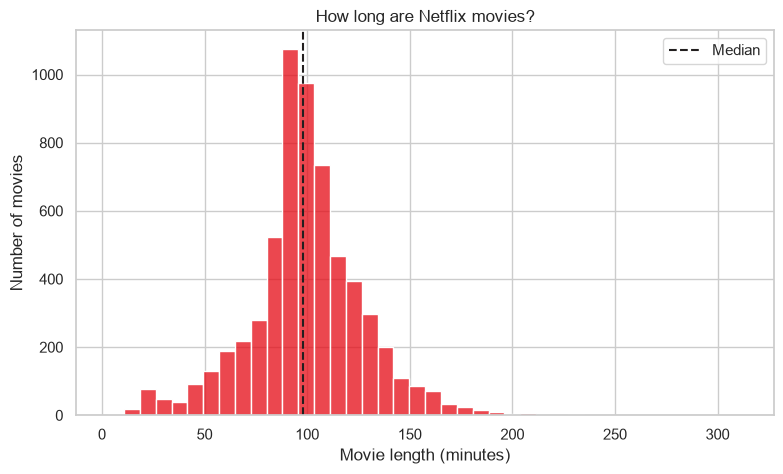

Mean: 99.6 | Median: 98.0 | Skew: 0.2


In [15]:
plt.figure(figsize=(9, 5))
sns.histplot(movies["duration_min"], bins=40, color=NETFLIX_RED)
plt.axvline(movies["duration_min"].median(), color=DARK, linestyle="--", label="Median")
plt.title("How long are Netflix movies?")
plt.xlabel("Movie length (minutes)")
plt.ylabel("Number of movies")
plt.legend()
plt.show()

print("Mean:", round(movies["duration_min"].mean(), 1), "| Median:", movies["duration_min"].median(), "| Skew:", round(movies["duration_min"].skew(), 2))

**What I found:** the shape is a single hump centred around 90 to 100 minutes. It is close to balanced with a slight lean to the right (skew = 0.20): the mean (99.6) is a little above the median (98) because a few very long movies pull it up.

## Task 12: Count plot

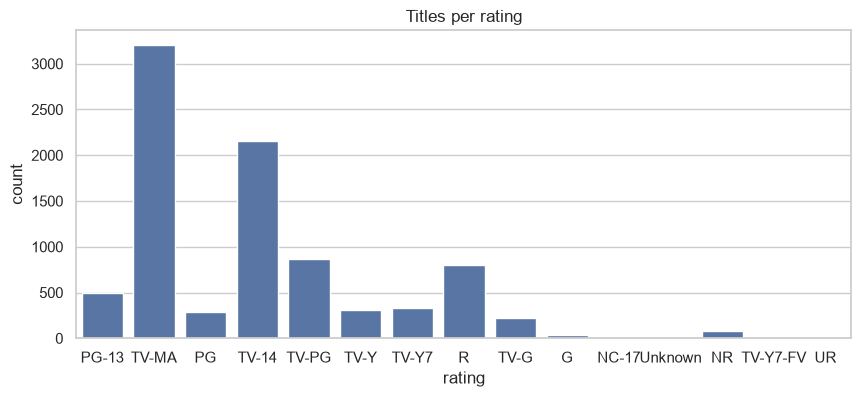

In [16]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="rating")
plt.title("Titles per rating")
plt.show()

**What I found:** **TV-MA** (mature audiences) is the most common rating with **3,205 titles (36%)**, followed by TV-14 (2,157) and TV-PG (861). Several ratings are very rare (NC-17, UR, Unknown). This is a plain first version; I improve it in Task 17.

## Task 13: Box plot

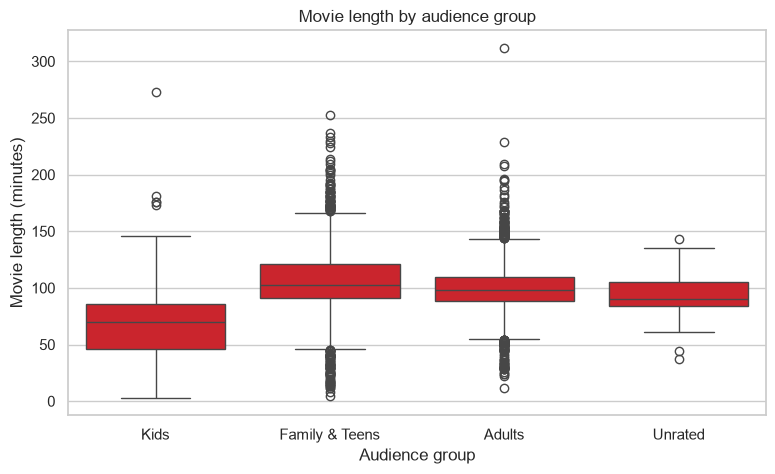

audience
Kids               69.5
Family & Teens    103.0
Adults             98.0
Unrated            90.0
Name: duration_min, dtype: float64


In [17]:
order = ["Kids", "Family & Teens", "Adults", "Unrated"]

plt.figure(figsize=(9, 5))
sns.boxplot(data=movies, x="audience", y="duration_min", order=order, color=NETFLIX_RED)
plt.title("Movie length by audience group")
plt.xlabel("Audience group")
plt.ylabel("Movie length (minutes)")
plt.show()

print(movies.groupby("audience")["duration_min"].median().reindex(order))

**What I found:** the median movie length is **70 min for Kids**, **103 min for Family & Teens** and **98 min for Adults**. Kids' movies are clearly shorter (about 28 to 34 minutes shorter than the other groups) and they also vary the most in length: the middle 50% of kids' movies spans 40 minutes, compared with 22 for adults.

## Task 14: Scatter plot

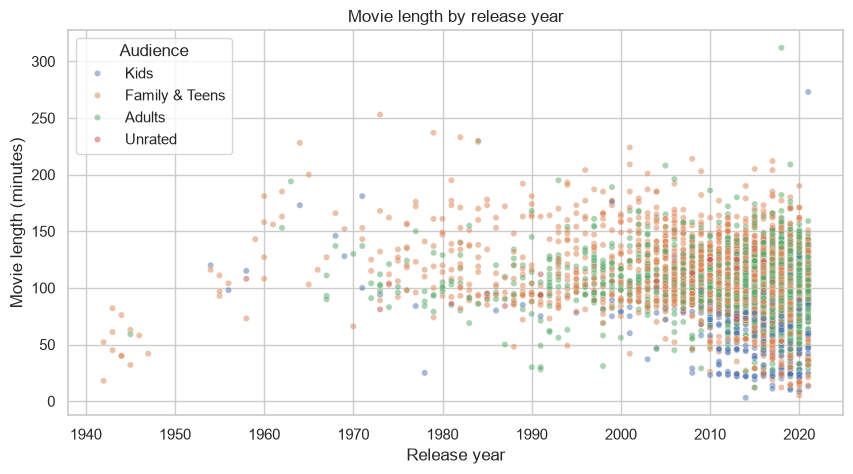

Correlation: -0.21


In [18]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=movies, x="release_year", y="duration_min", hue="audience",
                hue_order=["Kids", "Family & Teens", "Adults", "Unrated"], alpha=0.5, s=20)
plt.title("Movie length by release year")
plt.xlabel("Release year")
plt.ylabel("Movie length (minutes)")
plt.legend(title="Audience")
plt.show()

print("Correlation:", round(movies["release_year"].corr(movies["duration_min"]), 2))

**What I found:** they do **not** move together much. The correlation is **-0.21**, which is weak and negative: newer movies are slightly shorter. Most of the points are bunched in the recent years (2010 to 2021) because Netflix's catalogue is mostly recent. Older movies are far fewer.

## Task 15: Trend over time
There is a time column (`date_added`), so I show how many titles were added each year, split by type.

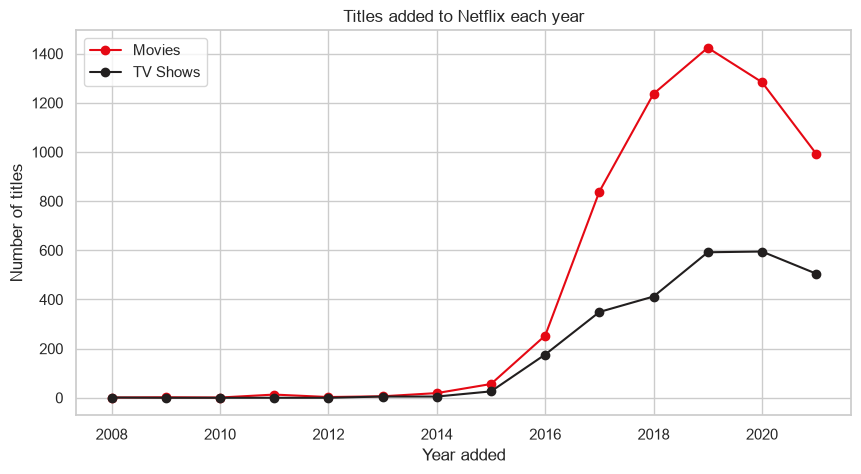

type        Movie  TV Show
year_added                
2016          253      176
2017          839      349
2018         1237      412
2019         1424      592
2020         1284      595
2021          993      505


In [19]:
per_year = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)

plt.figure(figsize=(10, 5))
plt.plot(per_year.index, per_year["Movie"], marker="o", color=NETFLIX_RED, label="Movies")
plt.plot(per_year.index, per_year["TV Show"], marker="o", color=DARK, label="TV Shows")
plt.title("Titles added to Netflix each year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

print(per_year.tail(6))

**What I found:** very few titles were added before 2015 (under 100 a year), then the number jumped in 2016 and kept rising. The peak was **2019** with **2,016** titles (1,424 movies and 592 TV shows). **98%** of all titles were added from 2016 onwards. The drop in 2020 and 2021 is partly because the data ends in September 2021, so 2021 is an incomplete year.

## Task 16: Correlation heatmap

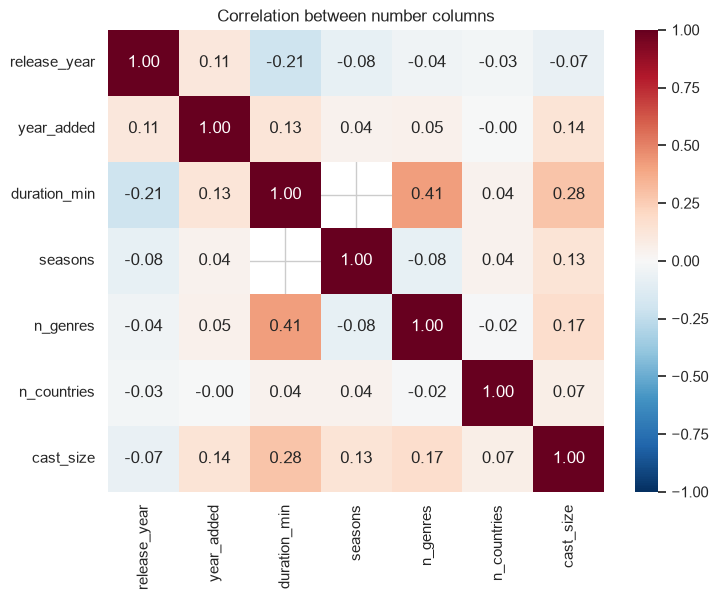

Strongest relationship: duration_min and n_genres (r = 0.41)


In [20]:
num_cols = ["release_year", "year_added", "duration_min", "seasons", "n_genres", "n_countries", "cast_size"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation between number columns")
plt.show()

# strongest pair (ignoring the diagonal and repeats)
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().abs().sort_values(ascending=False)
a, b = pairs.index[0]
print(f"Strongest relationship: {a} and {b} (r = {corr.loc[a, b]:.2f})")

**What I found:** the strongest relationship is between **`duration_min` and `n_genres`** (r = 0.41). The next strongest is `duration_min` and `cast_size` (r = 0.28); all other pairs are weaker, so the number columns here are mostly independent. Blank cells mean the pair never appears together (movies have minutes, TV shows have seasons).

# Part D: Tell the story and share it

## Task 17: Make one chart better
I improve the plain rating count plot from Task 12: sorted bars, a clear title, readable labels, colours that show the audience group, and the count written on each bar.

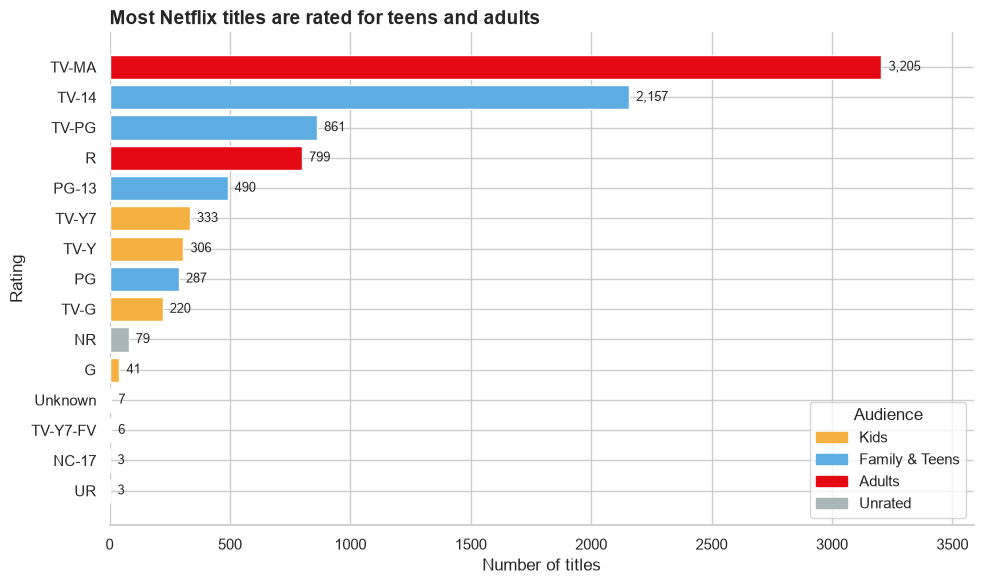

In [21]:
counts = df["rating"].value_counts()
colors_map = {"Kids": "#F5B041", "Family & Teens": "#5DADE2", "Adults": NETFLIX_RED, "Unrated": "#AAB7B8"}
bar_colors = [colors_map[audience(r)] for r in counts.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(counts.index[::-1], counts.values[::-1], color=bar_colors[::-1])

for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 30, i, f"{v:,}", va="center", fontsize=9)

ax.set_title("Most Netflix titles are rated for teens and adults", fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Number of titles")
ax.set_ylabel("Rating")
ax.set_xlim(0, counts.max() * 1.12)
sns.despine(left=True)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in colors_map.items()], title="Audience", loc="lower right")
plt.tight_layout()
plt.show()

**What I found:** compared with Task 12, the bars are sorted from most to least common, the labels are horizontal and easy to read, the count is written on each bar, and the colour shows the audience group. The title now states the message of the chart instead of just describing it. The big red bars (adult ratings) make it clear where most of the catalogue sits.

## Task 18: Findings

In [22]:
print("Movies share:", round((df['type'] == 'Movie').mean() * 100, 1), "%")
print("Median movie length:", movies["duration_min"].median(), "min")
print("Adult share:", round((df['audience'] == 'Adults').mean() * 100, 1), "%")
print("Single-season TV shows:", round((tv['seasons'] == 1).mean() * 100, 1), "%")
print("Added in 2016 or later:", round((df['year_added'] >= 2016).mean() * 100, 1), "%")
print("US share of titles with a known country:", round(df.loc[df['country'] != 'Unknown', 'country'].str.contains('United States').mean() * 100, 1), "%")

Movies share: 69.7 %
Median movie length: 98.0 min
Adult share: 45.5 %
Single-season TV shows: 67.3 %
Added in 2016 or later: 98.4 %
US share of titles with a known country: 46.2 %


**Findings (in plain English):**

1. **Movies dominate the catalogue.** About **70%** of titles are movies (6,131 movies vs 2,666 TV shows).
2. **A typical movie is about 98 minutes long.** Kids' movies are shorter (median 70 min) than adult movies (median 98 min).
3. **Most TV shows are short-lived.** About **67%** of TV shows have only 1 season.
4. **Most of the catalogue is aimed at adults.** About **46%** of titles carry an adult rating (TV-MA, R, NC-17), while only about **10%** are for kids.
5. **Netflix grew very fast after 2015.** **98%** of titles were added in 2016 or later, with the peak in 2019 (2,016 titles).
6. **The United States is the biggest producer:** it appears in about **46%** of titles with a known country.

In [21]:
# Save the clean data. The Streamlit app reads this file.
df.to_csv("netflix_clean.csv", index=False)
print("Saved netflix_clean.csv:", df.shape)

Saved netflix_clean.csv: (8797, 19)
